# Guava image translation — conditional diffusion experiment

Paired wrapped-to-unwrapped image generation using a compact PyTorch noise-prediction model. This is an exploratory implementation, not a production-quality diffusion model.

Dataset: 10 matched pairs for training and 10 for validation. The original experiment was configured for 8 epochs, 50 timesteps, and 128×128 images. Running the training cell trains a new model; saved outputs below are from a previous run.


In [1]:
# Install dependencies from requirements.txt before running this notebook.
# In a terminal: python -m pip install -r requirements.txt


In [2]:
import os
import cv2
import torch
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision

from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm import tqdm


In [3]:
from pathlib import Path

# Dataset is included in this repository.
DATASET_ROOT = str(Path.cwd() / "dataset")
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Dataset:", DATASET_ROOT)
print("Using device:", DEVICE)


Dataset: /Users/burcudogan/Desktop/Guava-Diffusion-Image-Translation/dataset
Using device: mps


In [4]:
IMAGE_SIZE = 128
# change to 256 for better quality

BATCH_SIZE = 4
# change to 8–16 later

EPOCHS = 8
# change to 150–300 later

TIMESTEPS = 50
# change to 200–500 for better diffusion quality


In [5]:
def preprocess_guava(img):
    """
    1. Fix EXIF orientation
    2. Remove top scale
    3. Find guava contour
    4. Deskew (rotation correction)
    5. Center crop with padding
    """
    img = ImageOps.exif_transpose(img)
    img = np.array(img)

    # --- remove measuring scale ---
    SCALE_HEIGHT = 60  # change to 80–100 if needed
    img = img[SCALE_HEIGHT:, :, :]

    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    blur = cv2.GaussianBlur(gray, (7, 7), 0)

    _, thresh = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return Image.fromarray(img)

    c = max(contours, key=cv2.contourArea)

    # --- rotation correction ---
    rect = cv2.minAreaRect(c)
    angle = rect[-1]
    if angle < -45:
        angle += 90

    (h, w) = img.shape[:2]
    center = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC)

    # --- crop bounding box after rotation ---
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, thresh = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    c = max(contours, key=cv2.contourArea)
    x, y, bw, bh = cv2.boundingRect(c)

    pad = int(0.2 * max(bw, bh))
    x = max(0, x - pad)
    y = max(0, y - pad)
    bw = min(img.shape[1] - x, bw + 2 * pad)
    bh = min(img.shape[0] - y, bh + 2 * pad)

    cropped = img[y:y+bh, x:x+bw]
    return Image.fromarray(cropped)


In [6]:
class GuavaDataset(Dataset):
    def __init__(self, root, split="train"):
        self.wrapped_dir = os.path.join(root, split, "wrapped")
        self.unwrapped_dir = os.path.join(root, split, "unwrapped")

        wrapped_files = set(f for f in os.listdir(self.wrapped_dir) if not f.startswith('.'))
        unwrapped_files = set(f for f in os.listdir(self.unwrapped_dir) if not f.startswith('.'))
        self.names = sorted(list(wrapped_files & unwrapped_files))

        self.transform = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.5]*3, [0.5]*3)
        ])

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]

        w = Image.open(os.path.join(self.wrapped_dir, name)).convert("RGB")
        u = Image.open(os.path.join(self.unwrapped_dir, name)).convert("RGB")

        w = preprocess_guava(w)
        u = preprocess_guava(u)

        return self.transform(w), self.transform(u)

In [7]:
def linear_beta_schedule(timesteps):
    return torch.linspace(1e-4, 0.015, timesteps)

betas = linear_beta_schedule(TIMESTEPS).to(DEVICE)
alphas = 1. - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)

def q_sample(x, t, noise):
    return (
        torch.sqrt(alphas_cumprod[t])[:, None, None, None] * x +
        torch.sqrt(1 - alphas_cumprod[t])[:, None, None, None] * noise
    )


In [8]:
class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        act = nn.SiLU  # smoother than ReLU

        self.enc1 = nn.Sequential(nn.Conv2d(6, 64, 3, padding=1), act())
        self.enc2 = nn.Sequential(nn.Conv2d(64, 128, 3, padding=1), act())
        self.enc3 = nn.Sequential(nn.Conv2d(128, 256, 3, padding=1), act())

        self.dec1 = nn.Sequential(nn.Conv2d(256, 128, 3, padding=1), act())
        self.dec2 = nn.Sequential(nn.Conv2d(128, 64, 3, padding=1), act())
        self.out = nn.Conv2d(64, 3, 1)

    def forward(self, x, cond):
        x = torch.cat([x, cond], dim=1)
        x = self.enc1(x)
        x = self.enc2(x)
        x = self.enc3(x)
        x = self.dec1(x)
        x = self.dec2(x)
        return self.out(x)


In [9]:
ds = GuavaDataset(DATASET_ROOT, "train")
dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True)
print(f"Training pairs: {len(ds)}; batches per epoch: {len(dl)}")

model = UNet().to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(EPOCHS):
    for w, u in tqdm(dl):
        w, u = w.to(DEVICE), u.to(DEVICE)

        t = torch.randint(0, TIMESTEPS, (w.size(0),), device=DEVICE)
        noise = torch.randn_like(u)

        noisy = q_sample(u, t, noise)
        pred = model(noisy, w)

        recon = noisy - pred
        loss = 0.7 * F.mse_loss(pred, noise) + 0.3 * F.l1_loss(recon, u)

        opt.zero_grad()
        loss.backward()
        opt.step()

    print(f"Epoch {epoch} | Loss {loss.item():.4f}")


Training pairs: 10; batches per epoch: 3


100%|██████████| 3/3 [00:09<00:00,  3.14s/it]


Epoch 0 | Loss 0.7307


100%|██████████| 3/3 [00:03<00:00,  1.21s/it]


Epoch 1 | Loss 0.7983


...

Epoch 5 | Loss 0.7687


100%|██████████| 3/3 [00:06<00:00,  2.04s/it]


Epoch 6 | Loss 0.8083


100%|██████████| 3/3 [00:06<00:00,  2.00s/it]

Epoch 7 | Loss 0.7664


In [10]:
@torch.no_grad()
def generate(model, wrapped):
    model.eval()
    x = torch.randn_like(wrapped)

    for t in reversed(range(TIMESTEPS)):
        x = (x - betas[t] * model(x, wrapped)) / torch.sqrt(alphas[t])

    x = torch.clamp(x, -1, 1)
    x = torchvision.transforms.functional.gaussian_blur(x, 5)
    return x


In [11]:
def show_triplet(w, g, u, n=4):
    def denorm(x): return (x * 0.5 + 0.5).clamp(0, 1)

    w, g, u = denorm(w[:n]), denorm(g[:n]), denorm(u[:n])
    grid = torchvision.utils.make_grid(
        torch.cat([w, g, u], dim=0),
        nrow=n
    )

    plt.figure(figsize=(12, 6))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    plt.show()


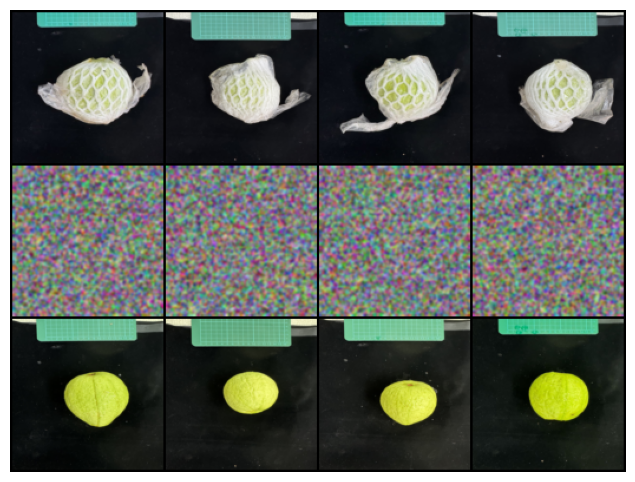

In [12]:
wrapped, target = next(iter(dl))
wrapped, target = wrapped.to(DEVICE), target.to(DEVICE)

generated = generate(model, wrapped)
show_triplet(wrapped.cpu(), generated.cpu(), target.cpu())


In [13]:
# scikit-image is listed in requirements.txt.


In [14]:
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr


In [15]:
@torch.no_grad()
def evaluate_model(model, dataloader):
    model.eval()

    ssim_scores = []
    psnr_scores = []
    l1_scores = []

    for wrapped, target in tqdm(dataloader):
        wrapped = wrapped.to(DEVICE)
        target = target.to(DEVICE)

        generated = generate(model, wrapped)

        # convert to numpy, denormalize
        gen = (generated.cpu().numpy() + 1) / 2
        tgt = (target.cpu().numpy() + 1) / 2

        for i in range(gen.shape[0]):
            g = gen[i].transpose(1, 2, 0)
            t = tgt[i].transpose(1, 2, 0)

            ssim_scores.append(
                ssim(t, g, channel_axis=2, data_range=1.0)
            )
            psnr_scores.append(
                psnr(t, g, data_range=1.0)
            )
            l1_scores.append(
                np.mean(np.abs(t - g))
            )

    return {
        "SSIM_mean": np.mean(ssim_scores),
        "PSNR_mean": np.mean(psnr_scores),
        "L1_mean": np.mean(l1_scores)
    }


## Previously recorded experiment results (not rerun here)

The original notebook's saved validation evaluation printed:

- **SSIM (mean): 0.04077663**
- **PSNR (mean): 7.751027341307285 dB**
- **L1 error (mean): 0.38922936**

These are **historical results**, not the output of a fresh run of this packaged notebook. The evaluation code below prints newly computed values after model training. Saved training logs and the original comparison image are retained for reference.


In [16]:
val_ds = GuavaDataset(DATASET_ROOT, "val")
val_dl = DataLoader(val_ds, batch_size=4, shuffle=False)

metrics = evaluate_model(model, val_dl)
print("Validation pairs:", len(val_ds))
print(f"SSIM: {float(metrics['SSIM_mean']):.6f}")
print(f"PSNR: {float(metrics['PSNR_mean']):.6f} dB")
print(f"Mean L1 error: {float(metrics['L1_mean']):.6f}")


100%|██████████| 3/3 [00:15<00:00,  5.16s/it]

Validation pairs: 10
SSIM: 0.050045
PSNR: 8.604150 dB
Mean L1 error: 0.351361


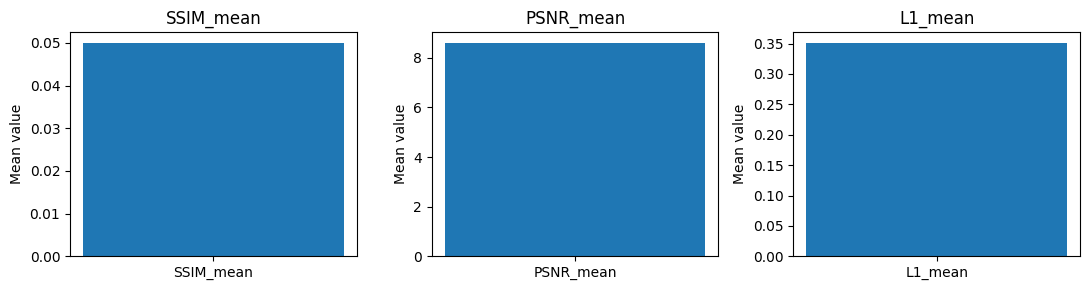

In [17]:
# Plot the aggregate evaluation metrics (not a distribution).
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, (label, value) in zip(axes, metrics.items()):
    ax.bar([label], [float(value)])
    ax.set_title(label)
    ax.set_ylabel("Mean value")
plt.tight_layout()
plt.show()
